# **STEP 1 — Dataset Setup & Understanding**

Load the datasets

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving tmdb_5000_credits.csv to tmdb_5000_credits.csv
Saving tmdb_5000_movies.csv to tmdb_5000_movies.csv


In [ ]:
import pandas as pd
import numpy as np

# Load the datasets
movies = pd.read_csv("tmdb_5000_movies.csv")

credits = pd.read_csv("tmdb_5000_credits.csv")

# Check the data types
print("Movies type:", type(movies))
print("Credits type:", type(credits))

# Check dataset sizes
print("Movies Dataset Shape:", movies.shape)
print("Credits Dataset Shape:", credits.shape)

Movies type: <class 'pandas.core.frame.DataFrame'>
Credits type: <class 'pandas.core.frame.DataFrame'>
Movies Dataset Shape: (4803, 20)
Credits Dataset Shape: (4803, 4)


Understand the columns

In [ ]:
print("Movies Columns:")
print(movies.columns.tolist())

print("\nCredits Columns:")
print(credits.columns.tolist())

Movies Columns:
['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language', 'original_title', 'overview', 'popularity', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'vote_average', 'vote_count']

Credits Columns:
['movie_id', 'title', 'cast', 'crew']


Look at sample data

In [ ]:
print(movies.head())

      budget                                             genres  \
0  237000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
1  300000000  [{"id": 12, "name": "Adventure"}, {"id": 14, "...   
2  245000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
3  250000000  [{"id": 28, "name": "Action"}, {"id": 80, "nam...   
4  260000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   

                                       homepage      id  \
0                   http://www.avatarmovie.com/   19995   
1  http://disney.go.com/disneypictures/pirates/     285   
2   http://www.sonypictures.com/movies/spectre/  206647   
3            http://www.thedarkknightrises.com/   49026   
4          http://movies.disney.com/john-carter   49529   

                                            keywords original_language  \
0  [{"id": 1463, "name": "culture clash"}, {"id":...                en   
1  [{"id": 270, "name": "ocean"}, {"id": 726, "na...                en   
2  [{"id": 470, "nam

In [ ]:
print(credits.head())

   movie_id                                     title  \
0     19995                                    Avatar   
1       285  Pirates of the Caribbean: At World's End   
2    206647                                   Spectre   
3     49026                     The Dark Knight Rises   
4     49529                               John Carter   

                                                cast  \
0  [{"cast_id": 242, "character": "Jake Sully", "...   
1  [{"cast_id": 4, "character": "Captain Jack Spa...   
2  [{"cast_id": 1, "character": "James Bond", "cr...   
3  [{"cast_id": 2, "character": "Bruce Wayne / Ba...   
4  [{"cast_id": 5, "character": "John Carter", "c...   

                                                crew  
0  [{"credit_id": "52fe48009251416c750aca23", "de...  
1  [{"credit_id": "52fe4232c3a36847f800b579", "de...  
2  [{"credit_id": "54805967c3a36829b5002c41", "de...  
3  [{"credit_id": "52fe4781c3a36847f81398c3", "de...  
4  [{"credit_id": "52fe479ac3a36847f813eaa3",

Check data types

In [ ]:
print(movies.dtypes)

budget                    int64
genres                   object
homepage                 object
id                        int64
keywords                 object
original_language        object
original_title           object
overview                 object
popularity              float64
production_companies     object
production_countries     object
release_date             object
revenue                   int64
runtime                 float64
spoken_languages         object
status                   object
tagline                  object
title                    object
vote_average            float64
vote_count                int64
dtype: object


In [ ]:
print(credits.dtypes)

movie_id     int64
title       object
cast        object
crew        object
dtype: object


Check missing values

In [ ]:
print("Missing values in Movies:")
print(movies.isnull().sum())

print("\nMissing values in Credits:")
print(credits.isnull().sum())

Missing values in Movies:
budget                     0
genres                     0
homepage                3091
id                         0
keywords                   0
original_language          0
original_title             0
overview                   3
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                  844
title                      0
vote_average               0
vote_count                 0
dtype: int64

Missing values in Credits:
movie_id    0
title       0
cast        0
crew        0
dtype: int64


Check duplicate records

In [ ]:
print("Duplicate rows in Movies:", movies.duplicated().sum())
print("Duplicate rows in Credits:", credits.duplicated().sum())

Duplicate rows in Movies: 0
Duplicate rows in Credits: 0


How will we connect the two datasets?

In [ ]:
movies.merge(credits, left_on="id", right_on="movie_id")

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,spoken_languages,status,tagline,title_x,vote_average,vote_count,movie_id,title_y,cast,crew
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,19995,Avatar,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,285,Pirates of the Caribbean: At World's End,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...",...,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,206647,Spectre,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,49026,The Dark Knight Rises,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,49529,John Carter,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4798,220000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",NaN,9367,"[{""id"": 5616, ""name"": ""united states\u2013mexi...",es,El Mariachi,El Mariachi just wants to play his guitar and ...,14.269792,"[{""name"": ""Columbia Pictures"", ""id"": 5}]",...,"[{""iso_639_1"": ""es"", ""name"": ""Espa\u00f1ol""}]",Released,"He didn't come looking for trouble, but troubl...",El Mariachi,6.6,238,9367,El Mariachi,"[{""cast_id"": 1, ""character"": ""El Mariachi"", ""c...","[{""credit_id"": ""52fe44eec3a36847f80b280b"", ""de..."
4799,9000,"[{""id"": 35, ""name"": ""Comedy""}, {""id"": 10749, ""...",NaN,72766,[],en,Newlyweds,A newlywed couple's honeymoon is upended by th...,0.642552,[],...,[],Released,A newlywed couple's honeymoon is upended by th...,Newlyweds,5.9,5,72766,Newlyweds,"[

# **STEP 2 — Data Cleaning & Merging**

First, select the useful columns

In [ ]:
# Select only the columns needed for our project

movies_clean = movies[
    ['id', 'title', 'genres', 'keywords', 'overview']
].copy()

credits_clean = credits[
    ['movie_id', 'cast', 'crew']
].copy()

print("Movies Clean Shape:", movies_clean.shape)
print("Credits Clean Shape:", credits_clean.shape)

Movies Clean Shape: (4803, 5)
Credits Clean Shape: (4803, 3)


Merge the two datasets

In [ ]:
# Merge the two datasets

movies_clean = movies_clean.merge(
    credits_clean,
    left_on='id',
    right_on='movie_id'
)

print("Merged Dataset Shape:", movies_clean.shape)

Merged Dataset Shape: (4803, 8)


Check the merged data

In [ ]:
movies_clean.head()

,id,title,genres,keywords,overview,movie_id,cast,crew
0,19995,Avatar,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...","In the 22nd century, a paraplegic Marine is di...",19995,"[{""cast_id"": 242, ""character"": ""Jake Sully"", ""...","[{""credit_id"": ""52fe48009251416c750aca23"", ""de..."
1,285,Pirates of the Caribbean: At World's End,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...","Captain Barbossa, long believed to be dead, ha...",285,"[{""cast_id"": 4, ""character"": ""Captain Jack Spa...","[{""credit_id"": ""52fe4232c3a36847f800b579"", ""de..."
2,206647,Spectre,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",A cryptic message from Bond’s past sends him o...,206647,"[{""cast_id"": 1, ""character"": ""James Bond"", ""cr...","[{""credit_id"": ""54805967c3a36829b5002c41"", ""de..."
3,49026,The Dark Knight Rises,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...","[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",Following the death of District Attorney Harve...,49026,"[{""cast_id"": 2, ""character"": ""Bruce Wayne / Ba...","[{""credit_id"": ""52fe4781c3a36847f81398c3"", ""de..."
4,49529,John Carter,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[{""id"": 818, ""name"": ""based on novel""}, {""id"":...","John Carter is a war-weary, former military ca...",49529,"[{""cast_id"": 5, ""character"": ""John Carter"", ""c...","[{""credit_id"": ""52fe479ac3a36847f813eaa3"", ""de..."


In [ ]:
print(movies_clean.columns.tolist())

['id', 'title', 'genres', 'keywords', 'overview', 'movie_id', 'cast', 'crew']


Check missing values

In [ ]:
print(movies_clean[
    ['title', 'genres', 'keywords', 'overview', 'cast', 'crew']
].isnull().sum())

title       0
genres      0
keywords    0
overview    3
cast        0
crew        0
dtype: int64


Handle missing overview

In [ ]:
movies_clean['overview'] = movies_clean['overview'].fillna('')

In [ ]:
print(movies_clean['overview'].isnull().sum())

0


Create a helper function for genres and keywords

In [ ]:
import ast

In [ ]:
def convert(text):
    result = []

    for item in ast.literal_eval(text):
        result.append(item['name'])

    return result

Apply it to genres and keywords

In [ ]:
movies_clean['genres'] = movies_clean['genres'].apply(convert)

movies_clean['keywords'] = movies_clean['keywords'].apply(convert)

In [ ]:
movies_clean[['title', 'genres', 'keywords']].head()

,title,genres,keywords
0,Avatar,"[Action, Adventure, Fantasy, Science Fiction]","[culture clash, future, space war, space colon..."
1,Pirates of the Caribbean: At World's End,"[Adventure, Fantasy, Action]","[ocean, drug abuse, exotic island, east india ..."
2,Spectre,"[Action, Adventure, Crime]","[spy, based on novel, secret agent, sequel, mi..."
3,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]","[dc comics, crime fighter, terrorist, secret i..."
4,John Carter,"[Action, Adventure, Science Fiction]","[based on novel, mars, medallion, space travel..."


final checks

In [ ]:
print(movies_clean.shape)
print(movies_clean.columns.tolist())
print(movies_clean[['title', 'genres', 'keywords']].head())

(4803, 8)
['id', 'title', 'genres', 'keywords', 'overview', 'movie_id', 'cast', 'crew']
                                      title  \
0                                    Avatar   
1  Pirates of the Caribbean: At World's End   
2                                   Spectre   
3                     The Dark Knight Rises   
4                               John Carter   

                                          genres  \
0  [Action, Adventure, Fantasy, Science Fiction]   
1                   [Adventure, Fantasy, Action]   
2                     [Action, Adventure, Crime]   
3               [Action, Crime, Drama, Thriller]   
4           [Action, Adventure, Science Fiction]   

                                            keywords  
0  [culture clash, future, space war, space colon...  
1  [ocean, drug abuse, exotic island, east india ...  
2  [spy, based on novel, secret agent, sequel, mi...  
3  [dc comics, crime fighter, terrorist, secret i...  
4  [based on novel, mars, medallion, spac

Extract Cast

In [ ]:
def convert_cast(text):
    result = []

    for item in ast.literal_eval(text):
        result.append(item['name'])

    # Keep only the first 3 cast members
    return result[:3]

In [ ]:
movies_clean['cast'] = movies_clean['cast'].apply(convert_cast)

In [ ]:
movies_clean[['title', 'cast']].head()

,title,cast
0,Avatar,"[Sam Worthington, Zoe Saldana, Sigourney Weaver]"
1,Pirates of the Caribbean: At World's End,"[Johnny Depp, Orlando Bloom, Keira Knightley]"
2,Spectre,"[Daniel Craig, Christoph Waltz, Léa Seydoux]"
3,The Dark Knight Rises,"[Christian Bale, Michael Caine, Gary Oldman]"
4,John Carter,"[Taylor Kitsch, Lynn Collins, Samantha Morton]"


Extract the Director

In [ ]:
def fetch_director(text):
    result = []

    for item in ast.literal_eval(text):
        if item['job'] == 'Director':
            result.append(item['name'])

    return result

In [ ]:
movies_clean['director'] = movies_clean['crew'].apply(fetch_director)

In [ ]:
movies_clean[['title', 'director']].head()

,title,director
0,Avatar,[James Cameron]
1,Pirates of the Caribbean: At World's End,[Gore Verbinski]
2,Spectre,[Sam Mendes]
3,The Dark Knight Rises,[Christopher Nolan]
4,John Carter,[Andrew Stanton]


Remove the unnecessary columns

In [ ]:
movies_clean = movies_clean[
    ['title', 'genres', 'keywords', 'overview', 'cast', 'director']
]

In [ ]:
movies_clean.head()

,title,genres,keywords,overview,cast,director
0,Avatar,"[Action, Adventure, Fantasy, Science Fiction]","[culture clash, future, space war, space colon...","In the 22nd century, a paraplegic Marine is di...","[Sam Worthington, Zoe Saldana, Sigourney Weaver]",[James Cameron]
1,Pirates of the Caribbean: At World's End,"[Adventure, Fantasy, Action]","[ocean, drug abuse, exotic island, east india ...","Captain Barbossa, long believed to be dead, ha...","[Johnny Depp, Orlando Bloom, Keira Knightley]",[Gore Verbinski]
2,Spectre,"[Action, Adventure, Crime]","[spy, based on novel, secret agent, sequel, mi...",A cryptic message from Bond’s past sends him o...,"[Daniel Craig, Christoph Waltz, Léa Seydoux]",[Sam Mendes]
3,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]","[dc comics, crime fighter, terrorist, secret i...",Following the death of District Attorney Harve...,"[Christian Bale, Michael Caine, Gary Oldman]",[Christopher Nolan]
4,John Carter,"[Action, Adventure, Science Fiction]","[based on novel, mars, medallion, space travel...","John Carter is a war-weary, former military ca...","[Taylor Kitsch, Lynn Collins, Samantha Morton]",[Andrew Stanton]


Check our cleaned dataset

In [ ]:
print("Shape:", movies_clean.shape)

print("\nColumns:")
print(movies_clean.columns.tolist())

print("\nMissing Values:")
print(movies_clean.isnull().sum())

Shape: (4803, 6)

Columns:
['title', 'genres', 'keywords', 'overview', 'cast', 'director']

Missing Values:
title       0
genres      0
keywords    0
overview    0
cast        0
director    0
dtype: int64


# **STEP 3 — Exploratory Data Analysis (EDA)**

Basic Dataset Overview

In [ ]:
print("Number of Movies:", len(movies_clean))
print("Number of Features:", len(movies_clean.columns))

print("\nDataset Shape:")
print(movies_clean.shape)

print("\nColumns:")
print(movies_clean.columns.tolist())

Number of Movies: 4803
Number of Features: 6

Dataset Shape:
(4803, 6)

Columns:
['title', 'genres', 'keywords', 'overview', 'cast', 'director']


Check Missing Values

In [ ]:
missing_values = movies_clean.isnull().sum()

print(missing_values)

title       0
genres      0
keywords    0
overview    0
cast        0
director    0
dtype: int64


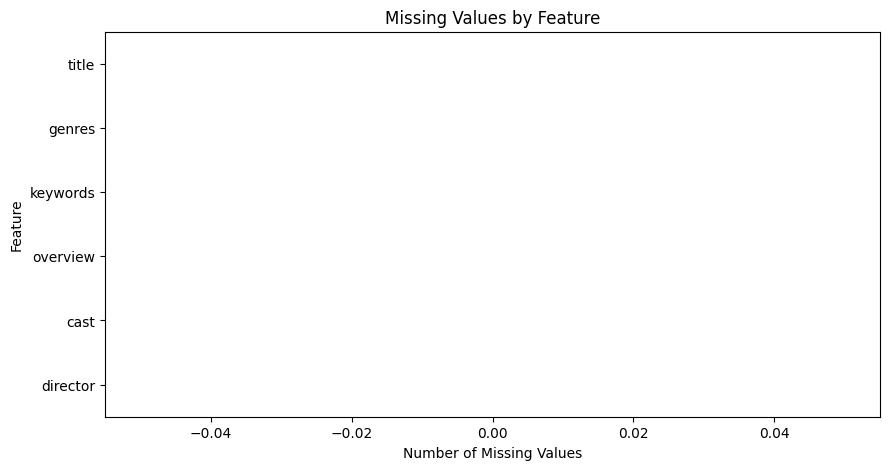

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_values.values,
    y=missing_values.index
)

plt.title("Missing Values by Feature")
plt.xlabel("Number of Missing Values")
plt.ylabel("Feature")

plt.show()

Genre Distribution

In [ ]:
from collections import Counter

genre_counts = Counter(
    genre
    for genre_list in movies_clean['genres']
    for genre in genre_list
)

genre_counts = genre_counts.most_common()

print(genre_counts)

[('Drama', 2297), ('Comedy', 1722), ('Thriller', 1274), ('Action', 1154), ('Romance', 894), ('Adventure', 790), ('Crime', 696), ('Science Fiction', 535), ('Horror', 519), ('Family', 513), ('Fantasy', 424), ('Mystery', 348), ('Animation', 234), ('History', 197), ('Music', 185), ('War', 144), ('Documentary', 110), ('Western', 82), ('Foreign', 34), ('TV Movie', 8)]


Visualize the genres

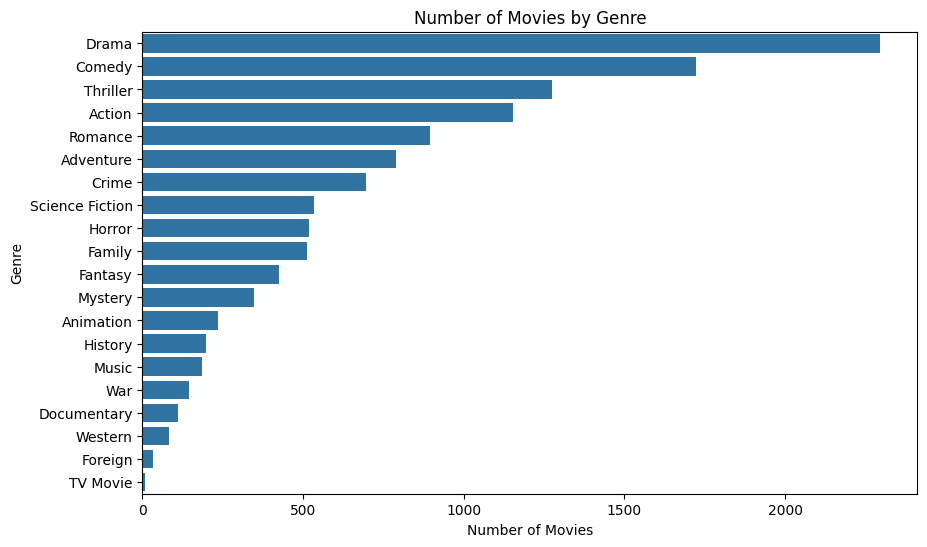

In [ ]:
genres_df = pd.DataFrame(
    genre_counts,
    columns=['Genre', 'Count']
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=genres_df,
    x='Count',
    y='Genre'
)

plt.title("Number of Movies by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.show()

Rating Distribution

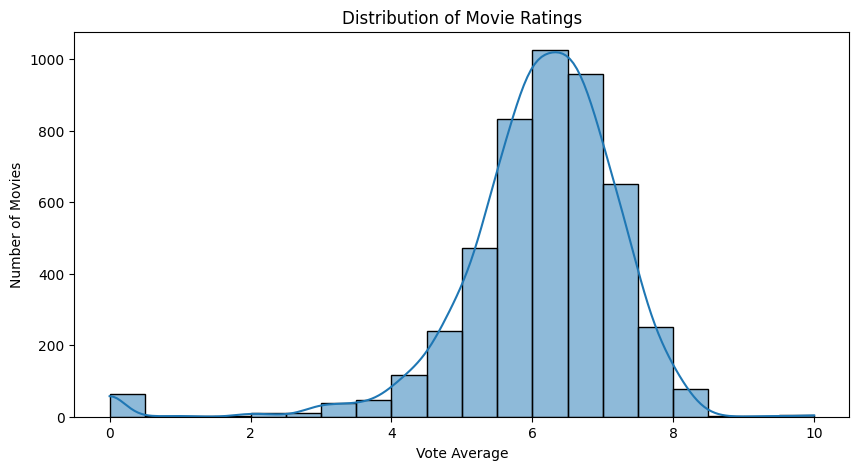

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    movies['vote_average'],
    bins=20,
    kde=True
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Vote Average")
plt.ylabel("Number of Movies")

plt.show()

Popularity Distribution

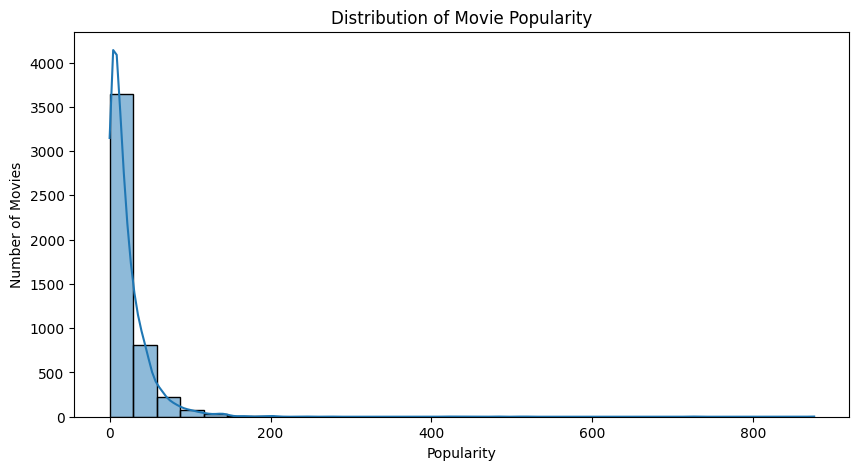

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    movies['popularity'],
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Popularity")
plt.xlabel("Popularity")
plt.ylabel("Number of Movies")

plt.show()

Movies by Release Year

In [ ]:
movies['release_date'] = pd.to_datetime(
    movies['release_date'],
    errors='coerce'
)

In [ ]:
movies['release_year'] = movies['release_date'].dt.year

In [ ]:
year_counts = movies['release_year'].value_counts().sort_index()

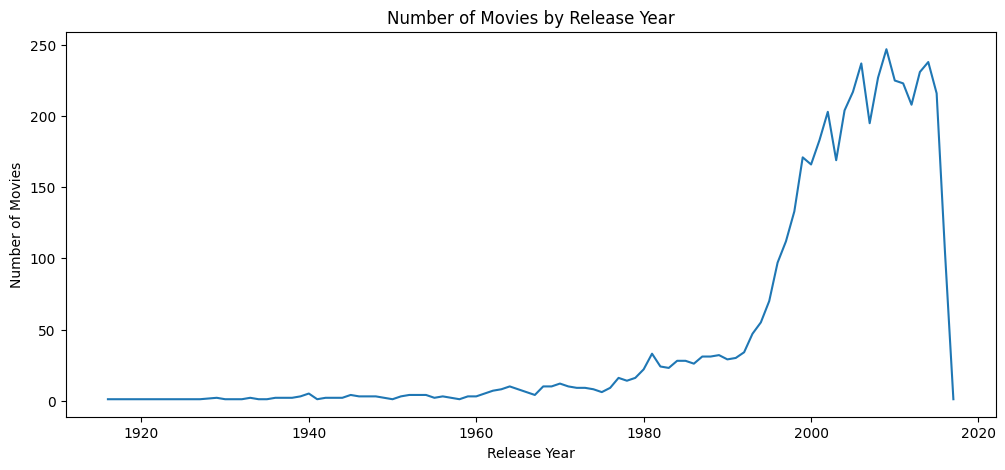

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    year_counts.index,
    year_counts.values
)

plt.title("Number of Movies by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")

plt.show()

Runtime Distribution

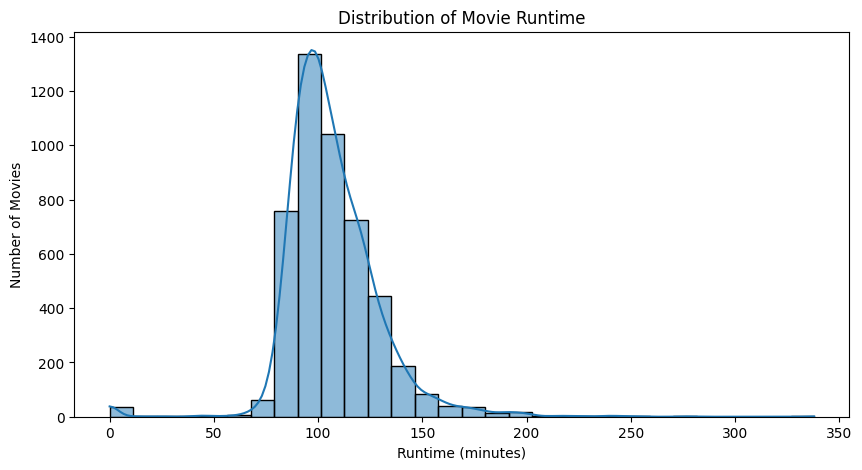

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    movies['runtime'].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Runtime")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of Movies")

plt.show()

Generate Simple EDA Statistics

In [ ]:
print("Average Rating:",
      round(movies['vote_average'].mean(), 2))

print("Average Runtime:",
      round(movies['runtime'].mean(), 2),
      "minutes")

print("Average Popularity:",
      round(movies['popularity'].mean(), 2))

print("Earliest Release Year:",
      int(movies['release_year'].min()))

print("Latest Release Year:",
      int(movies['release_year'].max()))

Average Rating: 6.09
Average Runtime: 106.88 minutes
Average Popularity: 21.49
Earliest Release Year: 1916
Latest Release Year: 2017


# **STEP 4 — Feature Engineering**

First, inspect one movie

In [ ]:
print("Title:")
print(movies_clean.loc[0, 'title'])

print("\nGenres:")
print(movies_clean.loc[0, 'genres'])

print("\nKeywords:")
print(movies_clean.loc[0, 'keywords'])

print("\nCast:")
print(movies_clean.loc[0, 'cast'])

print("\nDirector:")
print(movies_clean.loc[0, 'director'])

print("\nOverview:")
print(movies_clean.loc[0, 'overview'])

Title:
Avatar

Genres:
['Action', 'Adventure', 'Fantasy', 'Science Fiction']

Keywords:
['culture clash', 'future', 'space war', 'space colony', 'society', 'space travel', 'futuristic', 'romance', 'space', 'alien', 'tribe', 'alien planet', 'cgi', 'marine', 'soldier', 'battle', 'love affair', 'anti war', 'power relations', 'mind and soul', '3d']

Cast:
['Sam Worthington', 'Zoe Saldana', 'Sigourney Weaver']

Director:
['James Cameron']

Overview:
In the 22nd century, a paraplegic Marine is dispatched to the moon Pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization.


Convert lists into strings

In [ ]:
def list_to_string(value):
    return ' '.join(value)

In [ ]:
movies_clean['genres'] = movies_clean['genres'].apply(list_to_string)

movies_clean['keywords'] = movies_clean['keywords'].apply(list_to_string)

movies_clean['cast'] = movies_clean['cast'].apply(list_to_string)

movies_clean['director'] = movies_clean['director'].apply(list_to_string)

Check the result

In [ ]:
movies_clean.head()

,title,genres,keywords,overview,cast,director
0,Avatar,Action Adventure Fantasy Science Fiction,culture clash future space war space colony so...,"In the 22nd century, a paraplegic Marine is di...",Sam Worthington Zoe Saldana Sigourney Weaver,James Cameron
1,Pirates of the Caribbean: At World's End,Adventure Fantasy Action,ocean drug abuse exotic island east india trad...,"Captain Barbossa, long believed to be dead, ha...",Johnny Depp Orlando Bloom Keira Knightley,Gore Verbinski
2,Spectre,Action Adventure Crime,spy based on novel secret agent sequel mi6 bri...,A cryptic message from Bond’s past sends him o...,Daniel Craig Christoph Waltz Léa Seydoux,Sam Mendes
3,The Dark Knight Rises,Action Crime Drama Thriller,dc comics crime fighter terrorist secret ident...,Following the death of District Attorney Harve...,Christian Bale Michael Caine Gary Oldman,Christopher Nolan
4,John Carter,Action Adventure Science Fiction,based on novel mars medallion space travel pri...,"John Carter is a war-weary, former military ca...",Taylor Kitsch Lynn Collins Samantha Morton,Andrew Stanton


In [ ]:
print(movies_clean.loc[0, 'genres'])
print(movies_clean.loc[0, 'keywords'])
print(movies_clean.loc[0, 'cast'])
print(movies_clean.loc[0, 'director'])

Action Adventure Fantasy Science Fiction
culture clash future space war space colony society space travel futuristic romance space alien tribe alien planet cgi marine soldier battle love affair anti war power relations mind and soul 3d
Sam Worthington Zoe Saldana Sigourney Weaver
James Cameron


Create the tags column

In [ ]:
movies_clean['tags'] = (
    movies_clean['genres'] + ' ' +
    movies_clean['keywords'] + ' ' +
    movies_clean['cast'] + ' ' +
    movies_clean['director'] + ' ' +
    movies_clean['overview']
)

Look at our new feature

In [ ]:
print(movies_clean[['title', 'tags']].head())

                                      title  \
0                                    Avatar   
1  Pirates of the Caribbean: At World's End   
2                                   Spectre   
3                     The Dark Knight Rises   
4                               John Carter   

                                                tags  
0  Action Adventure Fantasy Science Fiction cultu...  
1  Adventure Fantasy Action ocean drug abuse exot...  
2  Action Adventure Crime spy based on novel secr...  
3  Action Crime Drama Thriller dc comics crime fi...  
4  Action Adventure Science Fiction based on nove...  


Check for missing tags

In [ ]:
print("Missing tags:", movies_clean['tags'].isnull().sum())

Missing tags: 0


In [ ]:
print("Empty tags:", (movies_clean['tags'].str.strip() == '').sum())

Empty tags: 0


Keep only what we need

In [ ]:
movies_clean[['title', 'tags']].head()

,title,tags
0,Avatar,Action Adventure Fantasy Science Fiction cultu...
1,Pirates of the Caribbean: At World's End,Adventure Fantasy Action ocean drug abuse exot...
2,Spectre,Action Adventure Crime spy based on novel secr...
3,The Dark Knight Rises,Action Crime Drama Thriller dc comics crime fi...
4,John Carter,Action Adventure Science Fiction based on nove...


STEP 4 Checkpoint

In [ ]:
print(movies_clean.shape)

print(movies_clean.columns.tolist())

print("\nFirst Movie:")
print(movies_clean.loc[0, 'title'])

print("\nTags:")
print(movies_clean.loc[0, 'tags'])

print("\nMissing Tags:")
print(movies_clean['tags'].isnull().sum())

(4803, 7)
['title', 'genres', 'keywords', 'overview', 'cast', 'director', 'tags']

First Movie:
Avatar

Tags:
Action Adventure Fantasy Science Fiction culture clash future space war space colony society space travel futuristic romance space alien tribe alien planet cgi marine soldier battle love affair anti war power relations mind and soul 3d Sam Worthington Zoe Saldana Sigourney Weaver James Cameron In the 22nd century, a paraplegic Marine is dispatched to the moon Pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization.

Missing Tags:
0


# **STEP 5 — Text Vectorization with CountVectorizer**

Import CountVectorizer

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

In [ ]:
cv = CountVectorizer(
    max_features=5000,
    stop_words='english'
)

Convert our tags into vectors

In [ ]:
vectors = cv.fit_transform(movies_clean['tags'])

Check the shape

In [ ]:
print("Vector Shape:", vectors.shape)

Vector Shape: (4803, 5000)


See the vocabulary

In [ ]:
print(cv.get_feature_names_out()[:50])

['000' '007' '10' '100' '11' '12' '13' '14' '15' '16' '17' '17th' '18'
 '18th' '19' '1930s' '1940s' '1950s' '1960s' '1970s' '1980s' '1985'
 '1990s' '19th' '20' '200' '2009' '20th' '21st' '24' '25' '30' '300' '3d'
 '40' '50' '500' '51' '60' '60s' '70' 'aaron' 'abandoned' 'abducted'
 'abigail' 'abilities' 'ability' 'able' 'aboard' 'abraham']


Look at one movie's vector

In [ ]:
print(vectors[0])

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 46 stored elements and shape (1, 5000)>
  Coords	Values
  (0, 69)	1
  (0, 97)	1
  (0, 1624)	1
  (0, 3942)	1
  (0, 1673)	1
  (0, 1077)	1
  (0, 848)	1
  (0, 1808)	1
  (0, 4198)	4
  (0, 4825)	2
  (0, 905)	1
  (0, 4167)	1
  (0, 4608)	1
  (0, 1809)	1
  (0, 3828)	1
  (0, 154)	3
  (0, 4625)	1
  (0, 3399)	1
  (0, 2803)	2
  (0, 4173)	1
  (0, 400)	1
  (0, 2720)	1
  (0, 101)	1
  (0, 228)	1
  (0, 3461)	1
  (0, 3685)	1
  (0, 2950)	1
  (0, 4190)	1
  (0, 33)	1
  (0, 3898)	1
  (0, 4992)	1
  (0, 3893)	1
  (0, 4103)	1
  (0, 4856)	1
  (0, 2351)	1
  (0, 658)	1
  (0, 750)	1
  (0, 1293)	1
  (0, 3000)	1
  (0, 4695)	1
  (0, 2969)	1
  (0, 4558)	1
  (0, 1735)	1
  (0, 3215)	1
  (0, 3536)	1
  (0, 841)	1


# **STEP 6 — Cosine Similarity**

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
similarity = cosine_similarity(vectors)

Check the similarity matrix

In [ ]:
print("Similarity Matrix Shape:", similarity.shape)

Similarity Matrix Shape: (4803, 4803)


Understand one row

In [ ]:
print(similarity[0])

[1.         0.06885304 0.04948717 ... 0.03142697 0.05410018 0.        ]


STEP 5 & 6 CHECKPOINT

In [ ]:
print("Vector Shape:", vectors.shape)
print("Similarity Shape:", similarity.shape)

print("\nFirst 20 Vocabulary Words:")
print(cv.get_feature_names_out()[:20])

print("\nSimilarity of Movie 0 with itself:")
print(similarity[0][0])

Vector Shape: (4803, 5000)
Similarity Shape: (4803, 4803)

First 20 Vocabulary Words:
['000' '007' '10' '100' '11' '12' '13' '14' '15' '16' '17' '17th' '18'
 '18th' '19' '1930s' '1940s' '1950s' '1960s' '1970s']

Similarity of Movie 0 with itself:
0.9999999999999991


# **STEP 7 — Build the Recommendation Function**

Create the movie index

In [ ]:
movie_indices = pd.Series(
    movies_clean.index,
    index=movies_clean['title']
).drop_duplicates()

print(movie_indices.head())

title
Avatar                                      0
Pirates of the Caribbean: At World's End    1
Spectre                                     2
The Dark Knight Rises                       3
John Carter                                 4
dtype: int64


Create the recommendation function

In [ ]:
def recommend(movie_name, n=5):

    # Check whether movie exists
    if movie_name not in movie_indices:
        print("Movie not found.")
        return

    # Get the index of the movie
    movie_index = movie_indices[movie_name]

    # Get similarity scores for that movie
    similarity_scores = list(enumerate(similarity[movie_index]))

    # Sort from highest similarity to lowest
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Display top similar movies
    print(f"\nMovies similar to: {movie_name}\n")

    count = 0

    for index, score in similarity_scores[1:]:
        print(f"{count + 1}. {movies_clean.iloc[index]['title']} "
              f"(Similarity: {score:.2f})")

        count += 1

        if count == n:
            break

Test it

In [ ]:
recommend("Avatar")


Movies similar to: Avatar

1. Aliens (Similarity: 0.48)
2. Moonraker (Similarity: 0.43)
3. Alien (Similarity: 0.42)
4. Alien³ (Similarity: 0.40)
5. Silent Running (Similarity: 0.39)


In [ ]:
recommend("The Dark Knight")


Movies similar to: The Dark Knight

1. The Dark Knight Rises (Similarity: 0.51)
2. Batman Begins (Similarity: 0.51)
3. Batman (Similarity: 0.36)
4. Batman & Robin (Similarity: 0.36)
5. Batman Forever (Similarity: 0.35)


In [ ]:
recommend("Tangled")


Movies similar to: Tangled

1. Into the Woods (Similarity: 0.21)
2. Enchanted (Similarity: 0.20)
3. Shrek (Similarity: 0.20)
4. The Princess and the Frog (Similarity: 0.19)
5. Shrek 2 (Similarity: 0.19)


# **STEP 8 — Make the Function User-Friendly**

In [ ]:
def recommend(movie_name, n=5):

    # Remove extra spaces and ignore capitalization
    movie_name = movie_name.strip().lower()

    # Create lowercase title mapping
    title_mapping = {
        title.lower(): index
        for title, index in movie_indices.items()
    }

    # Check whether movie exists
    if movie_name not in title_mapping:
        print("Movie not found. Please check the movie name.")
        return

    # Get movie index
    movie_index = title_mapping[movie_name]

    # Get similarity scores
    similarity_scores = list(
        enumerate(similarity[movie_index])
    )

    # Sort from highest to lowest
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    print(f"\nMovies similar to: {movies_clean.iloc[movie_index]['title']}\n")

    count = 0

    # Skip the movie itself
    for index, score in similarity_scores[1:]:

        print(
            f"{count + 1}. "
            f"{movies_clean.iloc[index]['title']} "
            f"(Similarity: {score:.2f})"
        )

        count += 1

        if count == n:
            break

In [ ]:
recommend("avatar")


Movies similar to: Avatar

1. Aliens (Similarity: 0.48)
2. Moonraker (Similarity: 0.43)
3. Alien (Similarity: 0.42)
4. Alien³ (Similarity: 0.40)
5. Silent Running (Similarity: 0.39)


Add Movie Details

In [ ]:
movie_details = movies[
    ['title', 'overview', 'vote_average', 'release_date']
].copy()

print(movie_details.head())

                                      title  \
0                                    Avatar   
1  Pirates of the Caribbean: At World's End   
2                                   Spectre   
3                     The Dark Knight Rises   
4                               John Carter   

                                            overview  vote_average  \
0  In the 22nd century, a paraplegic Marine is di...           7.2   
1  Captain Barbossa, long believed to be dead, ha...           6.9   
2  A cryptic message from Bond’s past sends him o...           6.3   
3  Following the death of District Attorney Harve...           7.6   
4  John Carter is a war-weary, former military ca...           6.1   

  release_date  
0   2009-12-10  
1   2007-05-19  
2   2015-10-26  
3   2012-07-16  
4   2012-03-07  


In [ ]:
movie_details['release_date'] = pd.to_datetime(
    movie_details['release_date'],
    errors='coerce'
)

movie_details['release_year'] = (
    movie_details['release_date'].dt.year
)

print(movie_details.head())

                                      title  \
0                                    Avatar   
1  Pirates of the Caribbean: At World's End   
2                                   Spectre   
3                     The Dark Knight Rises   
4                               John Carter   

                                            overview  vote_average  \
0  In the 22nd century, a paraplegic Marine is di...           7.2   
1  Captain Barbossa, long believed to be dead, ha...           6.9   
2  A cryptic message from Bond’s past sends him o...           6.3   
3  Following the death of District Attorney Harve...           7.6   
4  John Carter is a war-weary, former military ca...           6.1   

  release_date  release_year  
0   2009-12-10        2009.0  
1   2007-05-19        2007.0  
2   2015-10-26        2015.0  
3   2012-07-16        2012.0  
4   2012-03-07        2012.0  


Show Details for Recommended Movies

In [ ]:
def recommend(movie_name, n=5):

    movie_name = movie_name.strip().lower()

    # Create lowercase title mapping
    title_mapping = {
        title.lower(): index
        for title, index in movie_indices.items()
    }

    # Check movie exists
    if movie_name not in title_mapping:
        print("Movie not found. Please check the movie name.")
        return

    # Get selected movie index
    movie_index = title_mapping[movie_name]

    # Get similarity scores
    similarity_scores = list(
        enumerate(similarity[movie_index])
    )

    # Sort by similarity
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    print(f"\nMovies similar to: {movies_clean.iloc[movie_index]['title']}\n")

    count = 0

    for index, score in similarity_scores[1:]:

        # Get recommended movie details
        movie = movie_details.iloc[index]

        print(f"{count + 1}. {movie['title']}")
        print(f"   Similarity: {score:.2f}")
        print(f"   Rating: {movie['vote_average']}")
        print(f"   Release Year: {movie['release_year']}")
        print(f"   Overview: {movie['overview'][:150]}...")
        print()

        count += 1

        if count == n:
            break

In [ ]:
recommend("Avatar")


Movies similar to: Avatar

1. Aliens
   Similarity: 0.48
   Rating: 7.7
   Release Year: 1986.0
   Overview: When Ripley's lifepod is found by a salvage crew over 50 years later, she finds that terra-formers are on the very planet they found the alien species...

2. Moonraker
   Similarity: 0.43
   Rating: 5.9
   Release Year: 1979.0
   Overview: During the transportation of a Space Shuttle a Boeing 747 crashes in the Atlantic Ocean yet when they go to look for the destroyed shuttle it is not t...

3. Alien
   Similarity: 0.42
   Rating: 7.9
   Release Year: 1979.0
   Overview: During its return to the earth, commercial spaceship Nostromo intercepts a distress signal from a distant planet. When a three-member team of the crew...

4. Alien³
   Similarity: 0.40
   Rating: 6.2
   Release Year: 1992.0
   Overview: After escaping with Newt and Hicks from the alien planet, Ripley crash lands on Fiorina 161, a prison planet and host to a correctional facility. Unfo...

5. Silent Running
   S

# **STEP 9 — Test the Recommendation System**

In [ ]:
recommend("The Dark Knight")


Movies similar to: The Dark Knight

1. The Dark Knight Rises
   Similarity: 0.51
   Rating: 7.6
   Release Year: 2012.0
   Overview: Following the death of District Attorney Harvey Dent, Batman assumes responsibility for Dent's crimes to protect the late attorney's reputation and is...

2. Batman Begins
   Similarity: 0.51
   Rating: 7.5
   Release Year: 2005.0
   Overview: Driven by tragedy, billionaire Bruce Wayne dedicates his life to uncovering and defeating the corruption that plagues his home, Gotham City.  Unable t...

3. Batman
   Similarity: 0.36
   Rating: 7.0
   Release Year: 1989.0
   Overview: The Dark Knight of Gotham City begins his war on crime with his first major enemy being the clownishly homicidal Joker, who has seized control of Goth...

4. Batman & Robin
   Similarity: 0.36
   Rating: 4.2
   Release Year: 1997.0
   Overview: Along with crime-fighting partner Robin and new recruit Batgirl, Batman battles the dual threat of frosty genius Mr. Freeze and homicidal ho

In [ ]:
recommend("Iron Man")


Movies similar to: Iron Man

1. Iron Man 2
   Similarity: 0.59
   Rating: 6.6
   Release Year: 2010.0
   Overview: With the world now aware of his dual life as the armored superhero Iron Man, billionaire inventor Tony Stark faces pressure from the government, the p...

2. Iron Man 3
   Similarity: 0.57
   Rating: 6.8
   Release Year: 2013.0
   Overview: When Tony Stark's world is torn apart by a formidable terrorist called the Mandarin, he starts an odyssey of rebuilding and retribution....

3. Avengers: Age of Ultron
   Similarity: 0.48
   Rating: 7.3
   Release Year: 2015.0
   Overview: When Tony Stark tries to jumpstart a dormant peacekeeping program, things go awry and Earth’s Mightiest Heroes are put to the ultimate test as the fat...

4. Captain America: Civil War
   Similarity: 0.41
   Rating: 7.1
   Release Year: 2016.0
   Overview: Following the events of Age of Ultron, the collective governments of the world pass an act designed to regulate all superhuman activity. This pola

In [ ]:
recommend("Toy Story")


Movies similar to: Toy Story

1. Toy Story 2
   Similarity: 0.50
   Rating: 7.3
   Release Year: 1999.0
   Overview: Andy heads off to Cowboy Camp, leaving his toys to their own devices. Things shift into high gear when an obsessive toy collector named Al McWhiggen, ...

2. Toy Story 3
   Similarity: 0.47
   Rating: 7.6
   Release Year: 2010.0
   Overview: Woody, Buzz, and the rest of Andy's toys haven't been played with in years. With Andy about to go to college, the gang find themselves accidentally le...

3. Small Soldiers
   Similarity: 0.29
   Rating: 6.2
   Release Year: 1998.0
   Overview: When missile technology is used to enhance toy action figures, the toys soon begin to take their battle programming too seriously....

4. Everything You Always Wanted to Know About Sex *But Were Afraid to Ask
   Similarity: 0.28
   Rating: 6.6
   Release Year: 1972.0
   Overview: A collection of seven vignettes, which each address a question concerning human sexuality....

5. The 40 Year Old 

# **STEP 10 — Save Our Recommendation Model**

Save the movie data

In [ ]:
import pickle

with open("movie_dict.pkl", "wb") as file:
    pickle.dump(movies_clean, file)

print("movie_dict.pkl saved successfully!")

movie_dict.pkl saved successfully!


10.2 Save the similarity matrix

In [ ]:
with open("similarity.pkl", "wb") as file:
    pickle.dump(similarity, file)

print("similarity.pkl saved successfully!")

similarity.pkl saved successfully!


# **STEP 11 — Prepare Data for the Streamlit App**

Save movie details

In [ ]:
with open("movie_details.pkl", "wb") as file:
    pickle.dump(movie_details, file)

print("movie_details.pkl saved successfully!")

movie_details.pkl saved successfully!


Save the movie index

In [ ]:
with open("movie_indices.pkl", "wb") as file:
    pickle.dump(movie_indices, file)

print("movie_indices.pkl saved successfully!")

movie_indices.pkl saved successfully!
